# 02 · EMMA sensitivity analysis, scenarios S1-S5 (Table SM2, Figure SM14)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**

Re-runs the EMMA mass balance of `01_EMMA.ipynb` under five scenarios, each changing one methodological choice:

| Scenario | What changes | What it tests |
|---|---|---|
| **S1** | Nothing: δ¹⁸O + Cl⁻, published end-members, conservative-screened groundwater (n = 148) | Control; must reproduce the published numbers (MFR 53.5 %, regional MBR 6.4 %, front-slope MBR 40.1 %, 89.2 % valid) |
| **S2** | Samples flagged reactive by the Na/Cl screening are re-included | Influence of the screening decision |
| **S3** | Tracer pair δ²H + Cl⁻; end-member δ²H = measured means of the same defining samples (the values of Figure 11b) | Dependence on the choice of isotope |
| **S4** | All three end-members shifted by +1 SD in both tracers | Coherent worst-case end-member bias (upper) |
| **S5** | All three end-members shifted by −1 SD in both tracers (Cl⁻ floored at 0) | Coherent worst-case end-member bias (lower) |

| | |
|---|---|
| **Inputs** | `outputs/intermediate/data_EMMA1.xlsx`, `data/All_data1.xlsx` |
| **Outputs** | `outputs/tables/sensitivity_S1S5_results.csv` (Table SM2), `outputs/tables/sensitivity_S1S5_summary.md`, `outputs/figures/SM14_EMMA_sensitivity_S1S5` |

### <font color='orange'> **1) Packages and paths** </font>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_TABLES   = ROOT / "outputs" / "tables"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_TABLES, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)
FILE_EMMA1 = DIR_INTERMED / "data_EMMA1.xlsx"
FILE_RAW   = ROOT / "data" / "All_data1.xlsx"
for tag, fp in [("Isotopes", FILE_EMMA1), ("Raw data", FILE_RAW)]:
    assert fp.exists(), f"MISSING input file: {fp}"
    print(f"  {tag:9s} -> {fp.relative_to(ROOT)}")

# Column names exactly as in the data files
D18O = 'δ18O (‰ VSMOW)'
D2H = 'δ2H (‰ VSMOW)'
CL = 'Cl (mg/L)'
NA = 'Na (mg/L)'

# Published values (01_EMMA.ipynb) used as the S1 sanity check
PUB = {'n': 148, 'valid_pct': 89.2, 'MFR': 0.535, 'RegMBR': 0.064,
       'FSMBR': 0.401}

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


  Isotopes  -> outputs\intermediate\data_EMMA1.xlsx
  Raw data  -> data\All_data1.xlsx


### <font color='orange'> **2) Load and merge (same logic as 01_EMMA.ipynb, sections 2-3)** </font>

In [2]:
df_emma1 = pd.read_excel(FILE_EMMA1)
df_raw = pd.read_excel(FILE_RAW)

df_raw_sub = df_raw[['SampleID', NA, CL, 'EC (μS/cm)']].drop_duplicates(
    subset='SampleID')
df = df_emma1.merge(df_raw_sub, on='SampleID', how='left')
print(f'Merged dataset: {df.shape[0]} rows, Cl non-null = {df[CL].notna().sum()}')

Merged dataset: 345 rows, Cl non-null = 263


### <font color='orange'> **3) Na/Cl conservativeness screening (as in 01_EMMA.ipynb, section 4)** </font>

A sample is flagged "reactive" (Cl non-conservative) only if BOTH:
  Cl > 100 mg/L  AND  Na/Cl molar ratio < 0.7

In [3]:
M_NA, M_CL = 22.99, 35.45
mask_chem = df[NA].notna() & df[CL].notna()
ratio = (df.loc[mask_chem, NA] / M_NA) / (df.loc[mask_chem, CL] / M_CL)

df['reactive_Cl'] = False
df.loc[mask_chem, 'reactive_Cl'] = (
    (df.loc[mask_chem, CL] > 100) & (ratio < 0.7)
)
print(f'Reactive-flagged samples (all types): {df["reactive_Cl"].sum()}')

Reactive-flagged samples (all types): 12


### <font color='orange'> **4) End-member definitions (same rules as 01_EMMA.ipynb, section 6)** </font>

EM1 (MFR):            mean of 5 most depleted d18O stream/spring samples
EM2 (Regional MBR):   mean of 3 highest-Cl groundwater samples
EM3 (Front-slope MBR): mean of 5 most enriched d18O samples (GW, spring,
                       rain) with Cl < 100 mg/L
The pool is ALL samples with both d18O and Cl, so the end-members are the
same regardless of which EMMA target dataset a scenario uses.

In [4]:
pool = df.loc[df[D18O].notna() & df[CL].notna()].copy()

em1_samples = pool[pool['Type'].isin(['Stream', 'Spring'])].nsmallest(5, D18O)
em2_samples = pool[pool['Type'] == 'Groundwater'].nlargest(3, CL)
em3_samples = pool[
    pool['Type'].isin(['Groundwater', 'Spring', 'Rain']) & (pool[CL] < 100)
].nlargest(5, D18O)

def em_stats(samples, label):
    """Mean and SD of d18O, Cl and MEASURED d2H for one end-member."""
    d2h = samples[D2H].dropna()
    out = {
        'label': label,
        'd18O': samples[D18O].mean(), 'd18O_sd': samples[D18O].std(),
        'Cl': samples[CL].mean(), 'Cl_sd': samples[CL].std(),
        'd2H': d2h.mean(), 'd2H_sd': d2h.std(),
        'n': len(samples), 'n_d2H': len(d2h),
    }
    print(f"{label:22s}: d18O = {out['d18O']:6.2f} ± {out['d18O_sd']:.2f}, "
          f"Cl = {out['Cl']:7.1f} ± {out['Cl_sd']:.1f}, "
          f"d2H = {out['d2H']:6.1f} ± {out['d2H_sd']:.1f} "
          f"(n = {out['n']}, n_d2H = {out['n_d2H']})")
    return out

print('\nEnd-members (mean ± SD):')
EM1 = em_stats(em1_samples, 'EM1 (MFR)')
EM2 = em_stats(em2_samples, 'EM2 (Regional MBR)')
EM3 = em_stats(em3_samples, 'EM3 (Front-slope MBR)')


End-members (mean ± SD):
EM1 (MFR)             : d18O =  -9.07 ± 0.27, Cl =     6.3 ± 2.9, d2H =  -57.5 ± 2.8 (n = 5, n_d2H = 5)
EM2 (Regional MBR)    : d18O =  -4.87 ± 0.82, Cl =  1969.0 ± 180.5, d2H =  -33.9 ± 6.4 (n = 3, n_d2H = 3)
EM3 (Front-slope MBR) : d18O =  -4.70 ± 0.29, Cl =    11.6 ± 10.4, d2H =  -25.3 ± 4.6 (n = 5, n_d2H = 5)


### <font color='orange'> **5) Three-end-member mass balance (same equations as 01_EMMA.ipynb, section 8)** </font>

Unknowns Ra (EM1), Rb (EM2), Rc (EM3) from:
  Ra + Rb + Rc = 1
  tracer1_sample = Ra*t1_EM1 + Rb*t1_EM2 + Rc*t1_EM3
  tracer2_sample = Ra*t2_EM1 + Rb*t2_EM2 + Rc*t2_EM3
Written generically: t = isotope tracer (d18O or d2H), c = Cl.

In [5]:
def solve_3em(t_s, c_s, ems):
    """ems = [(t_EM1, c_EM1), (t_EM2, c_EM2), (t_EM3, c_EM3)].
    Returns (Ra, Rb, Rc)."""
    (ta, ca), (tb, cb), (tc, cc) = ems
    denom_a = (ta - tc) * (cb - cc) - (ca - cc) * (tb - tc)
    denom_b = (tb - tc) * (ca - cc) - (cb - cc) * (ta - tc)
    if abs(denom_a) < 1e-12 or abs(denom_b) < 1e-12:
        return np.nan, np.nan, np.nan
    Ra = ((t_s - tc) * (cb - cc) - (c_s - cc) * (tb - tc)) / denom_a
    Rb = ((t_s - tc) * (ca - cc) - (c_s - cc) * (ta - tc)) / denom_b
    Rc = 1.0 - Ra - Rb
    return Ra, Rb, Rc

def run_scenario(code, desc, data, tracer_col, ems):
    """Apply the mass balance to every sample in `data` and summarise.
    A sample is VALID if all three fractions are in [0, 1]."""
    res = np.array([solve_3em(t, c, ems)
                    for t, c in zip(data[tracer_col], data[CL])])
    ra, rb, rc = res[:, 0], res[:, 1], res[:, 2]
    valid = ((ra >= 0) & (ra <= 1) & (rb >= 0) & (rb <= 1) &
             (rc >= 0) & (rc <= 1))
    out = {
        'Scenario': code,
        'Description': desc,
        'n_samples': len(data),
        'n_valid': int(valid.sum()),
        'valid_pct': 100.0 * valid.sum() / len(data),
        'MFR_pct': 100.0 * ra[valid].mean(),
        'RegMBR_pct': 100.0 * rb[valid].mean(),
        'FSMBR_pct': 100.0 * rc[valid].mean(),
    }
    print(f"{code}: n = {out['n_samples']:3d}, valid = {out['valid_pct']:5.1f}%, "
          f"MFR = {out['MFR_pct']:5.1f}%, RegMBR = {out['RegMBR_pct']:4.1f}%, "
          f"FSMBR = {out['FSMBR_pct']:5.1f}%   ({desc})")
    return out

### <font color='orange'> **6) Scenario datasets and end-member coordinate sets** </font>

In [6]:
gw_both = df[(df['Type'] == 'Groundwater') & df[D18O].notna() & df[CL].notna()]

ds_S1 = gw_both[~gw_both['reactive_Cl']]          # published dataset
ds_S2 = gw_both                                   # screening relaxed
ds_S3 = ds_S1[ds_S1[D2H].notna()]                 # needs d2H as well

print(f'\nDatasets: S1/S4/S5 n = {len(ds_S1)}, '
      f'S2 n = {len(ds_S2)} (adds {len(ds_S2) - len(ds_S1)} reactive), '
      f'S3 n = {len(ds_S3)}')
assert len(ds_S1) == PUB['n'], (
    f'S1 dataset has {len(ds_S1)} samples, expected {PUB["n"]}. '
    'The data files changed since the published run, stop and check.')

ems_base = [(e['d18O'], e['Cl']) for e in (EM1, EM2, EM3)]
ems_d2H = [(e['d2H'], e['Cl']) for e in (EM1, EM2, EM3)]
ems_plus1 = [(e['d18O'] + e['d18O_sd'], e['Cl'] + e['Cl_sd'])
             for e in (EM1, EM2, EM3)]
ems_minus1 = [(e['d18O'] - e['d18O_sd'], max(0.0, e['Cl'] - e['Cl_sd']))
              for e in (EM1, EM2, EM3)]


Datasets: S1/S4/S5 n = 148, S2 n = 158 (adds 10 reactive), S3 n = 148


### <font color='orange'> **7) Run the five scenarios** </font>

In [7]:
print('\nScenario results (means over VALID samples only):')
rows = [
    run_scenario('S1', 'Baseline (published run)', ds_S1, D18O, ems_base),
    run_scenario('S2', 'Screening relaxed (reactive Cl included)',
                 ds_S2, D18O, ems_base),
    run_scenario('S3', 'Tracer pair d2H + Cl (measured EM d2H)',
                 ds_S3, D2H, ems_d2H),
    run_scenario('S4', 'End-members shifted +1 SD', ds_S1, D18O, ems_plus1),
    run_scenario('S5', 'End-members shifted -1 SD', ds_S1, D18O, ems_minus1),
]
results = pd.DataFrame(rows)

# Deviations from baseline, in percentage points
for col in ['MFR_pct', 'RegMBR_pct', 'FSMBR_pct']:
    results[f'd{col[:-4]}_vs_S1'] = results[col] - results.loc[0, col]

# ── S1 sanity check against the published numbers ──
s1 = results.iloc[0]
checks = [
    ('MFR', s1['MFR_pct'], 100 * PUB['MFR']),
    ('RegMBR', s1['RegMBR_pct'], 100 * PUB['RegMBR']),
    ('FSMBR', s1['FSMBR_pct'], 100 * PUB['FSMBR']),
    ('valid %', s1['valid_pct'], PUB['valid_pct']),
]
print('\nS1 sanity check vs published values:')
ok = True
for name, got, exp in checks:
    match = abs(got - exp) < 0.15   # allow rounding at 1 decimal
    ok &= match
    print(f"  {name:8s}: script = {got:5.2f}, published = {exp:5.2f} "
          f"-> {'OK' if match else 'MISMATCH'}")
print('S1 reproduces the published run.' if ok
      else 'WARNING: S1 does NOT reproduce the published run, investigate.')


Scenario results (means over VALID samples only):
S1: n = 148, valid =  89.2%, MFR =  53.5%, RegMBR =  6.4%, FSMBR =  40.1%   (Baseline (published run))
S2: n = 158, valid =  89.2%, MFR =  53.8%, RegMBR =  6.7%, FSMBR =  39.5%   (Screening relaxed (reactive Cl included))
S3: n = 148, valid =  87.8%, MFR =  58.4%, RegMBR =  6.3%, FSMBR =  35.4%   (Tracer pair d2H + Cl (measured EM d2H))
S4: n = 148, valid =  80.4%, MFR =  60.9%, RegMBR =  5.5%, FSMBR =  33.7%   (End-members shifted +1 SD)
S5: n = 148, valid =  93.2%, MFR =  48.1%, RegMBR =  7.0%, FSMBR =  44.8%   (End-members shifted -1 SD)

S1 sanity check vs published values:
  MFR     : script = 53.50, published = 53.50 -> OK
  RegMBR  : script =  6.40, published =  6.40 -> OK
  FSMBR   : script = 40.10, published = 40.10 -> OK
  valid % : script = 89.19, published = 89.20 -> OK
S1 reproduces the published run.


### <font color='orange'> **8) Exports: Table SM2, Figure SM14 and a summary** </font>


Saved: outputs\tables\sensitivity_S1S5_results.csv


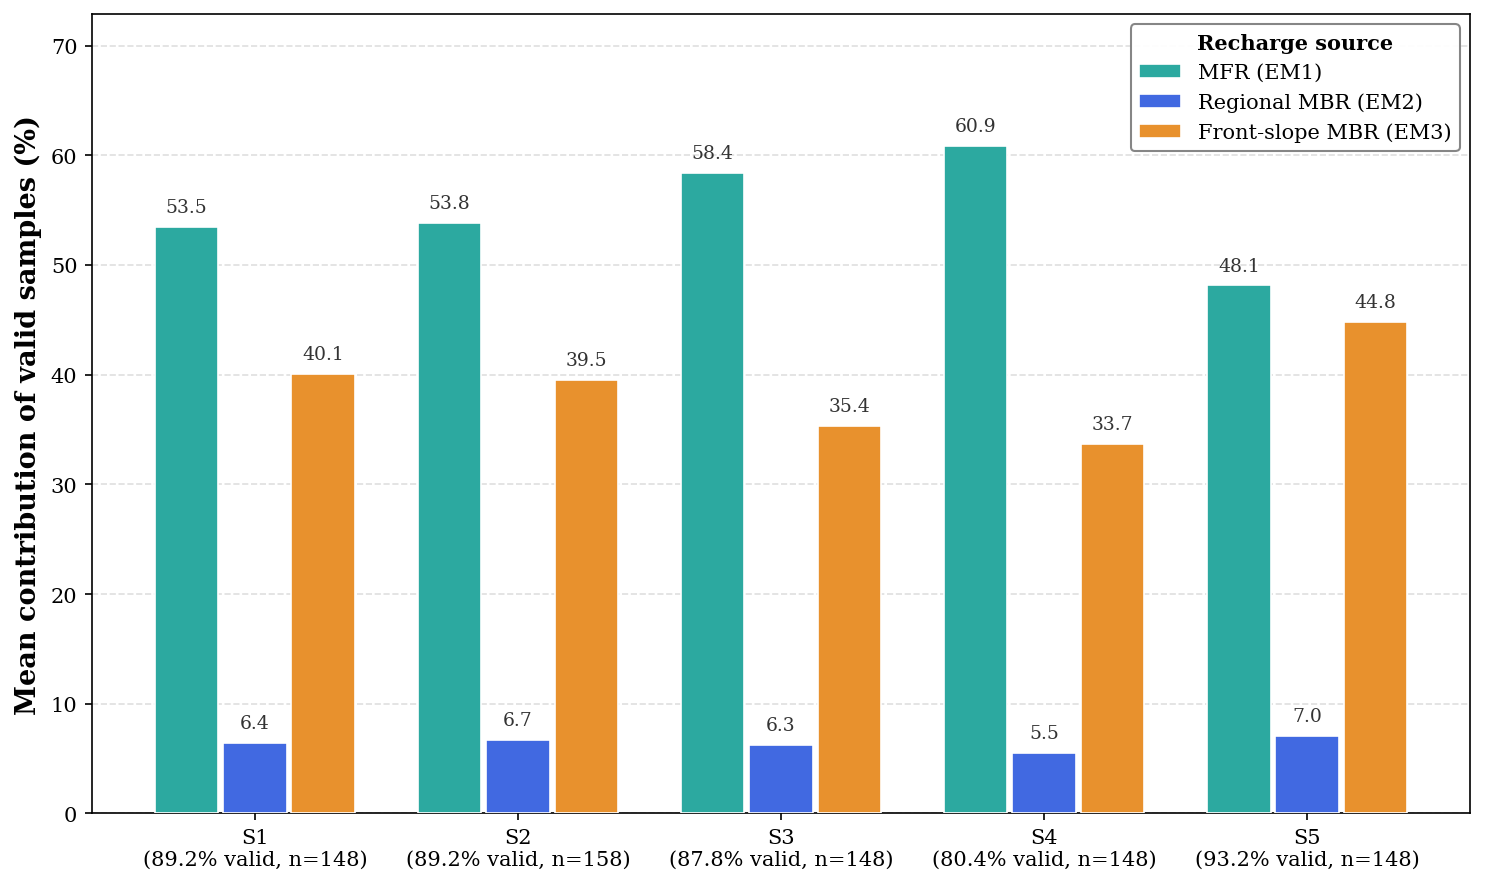

Saved: SM14_EMMA_sensitivity_S1S5.png
Saved: outputs\tables\sensitivity_S1S5_summary.md

✓ Matches the article: S1 reproduces the published apportionment; Table SM2 and Figure SM14 written.


In [8]:
csv_path = DIR_TABLES / 'sensitivity_S1S5_results.csv'
results.round(2).to_csv(csv_path, index=False)
print(f'\nSaved: {csv_path.relative_to(ROOT)}')

# ── grouped bar figure ──
plt.rcParams.update({'font.family': 'serif', 'figure.dpi': 150})
SOURCES = [('MFR_pct', 'MFR (EM1)', '#2ca9a0'),
           ('RegMBR_pct', 'Regional MBR (EM2)', '#4169e1'),
           ('FSMBR_pct', 'Front-slope MBR (EM3)', '#e8912d')]

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(results))
width = 0.26
for i, (col, label, color) in enumerate(SOURCES):
    vals = results[col].values
    bars = ax.bar(x + (i - 1) * width, vals, width * 0.93, label=label,
                  color=color, edgecolor='white', linewidth=0.8, zorder=3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.0, f'{v:.1f}',
                ha='center', va='bottom', fontsize=9, color='#333333')

ax.set_xticks(x)
ax.set_xticklabels([f"{r.Scenario}\n({r.valid_pct:.1f}% valid, "
                    f"n={r.n_samples})" for r in results.itertuples()],
                   fontsize=10)
ax.set_ylabel('Mean contribution of valid samples (%)',
              fontsize=13, fontweight='bold')
ax.set_ylim(0, max(results['MFR_pct'].max(), results['FSMBR_pct'].max()) + 12)
ax.grid(True, axis='y', ls='--', alpha=0.25, color='gray', zorder=0)
ax.legend(loc='upper right', fontsize=10, framealpha=0.95, edgecolor='gray',
          title='Recharge source', title_fontproperties={'weight': 'bold'})
fig.tight_layout()
fig.savefig(DIR_FIGURES / 'SM14_EMMA_sensitivity_S1S5.png',
            dpi=600, bbox_inches='tight')
plt.show()
print('Saved: SM14_EMMA_sensitivity_S1S5.png')

# ═════════════════════════════════════════════════════════════════════════
# Summary document: sensitivity_S1S5_summary.md
# Every number below is computed from `results`, so the document always
# matches the run that produced it.
# ═════════════════════════════════════════════════════════════════════════
max_dev = results[['dMFR_vs_S1', 'dRegMBR_vs_S1', 'dFSMBR_vs_S1']].abs().max()
S = {row.Scenario: row for row in results.itertuples()}
s1, s2, s3, s4, s5 = S['S1'], S['S2'], S['S3'], S['S4'], S['S5']

mfr_min, mfr_max = results['MFR_pct'].min(), results['MFR_pct'].max()
reg_min, reg_max = results['RegMBR_pct'].min(), results['RegMBR_pct'].max()
fs_min, fs_max = results['FSMBR_pct'].min(), results['FSMBR_pct'].max()
s2_max = results.loc[results['Scenario'] == 'S2',
                     ['dMFR_vs_S1', 'dRegMBR_vs_S1', 'dFSMBR_vs_S1']
                     ].abs().max().max()

def em_line(e):
    return (f"| {e['label']} | {e['d18O']:.2f} ± {e['d18O_sd']:.2f} | "
            f"{e['d2H']:.1f} ± {e['d2H_sd']:.1f} | "
            f"{e['Cl']:.1f} ± {e['Cl_sd']:.1f} | {e['n']} |")

md = []
md.append("""# Sensitivity analysis of the EMMA recharge apportionment (scenarios S1-S5)

Supplementary analysis of El Farchouni et al., Groundwater for Sustainable Development
(Table SM2, Figure SM14).

## 1. Purpose and rationale

The main workflow (01_EMMA.ipynb) apportions groundwater recharge in the
Haouz-Mejjate aquifer among three end-members, Mountain-Front Recharge (MFR),
regional Mountain-Block Recharge (MBR) and front-slope MBR, using a
three-end-member mass balance with two conservative tracers (δ18O and Cl). The
Monte Carlo error propagation already included in that workflow (N = 1000, each
end-member perturbed randomly within its standard deviation) quantifies the
effect of RANDOM end-member uncertainty. The present sensitivity analysis
complements it by testing the discrete METHODOLOGICAL CHOICES of the workflow.
Each scenario changes exactly one choice while keeping everything else
identical, so any difference in the outcome is attributable to that choice
alone:

- the Na/Cl conservativeness screening of the dataset (S2),
- the choice of isotopic tracer (S3),
- coherent worst-case shifts of all three end-members by +1 and -1 standard
  deviation (S4, S5).

Scenario S1 reproduces the published run exactly and serves as the control: it
proves that the sensitivity notebook implements the same screening, end-member
definitions and mass balance as the main workflow.

## 2. Baseline configuration being tested (published run)

- Dataset: groundwater samples with both δ18O and Cl measurements whose Cl
  passed the conservativeness screening (a sample is flagged reactive only if
  Cl > 100 mg/L AND Na/Cl molar ratio < 0.7), n = 148.
- End-members, defined from the extremes of the full sample pool (all water
  types with both tracers): EM1 (MFR) = mean of the 5 most δ18O-depleted stream
  and spring samples; EM2 (regional MBR) = mean of the 3 highest-Cl groundwater
  samples; EM3 (front-slope MBR) = mean of the 5 most δ18O-enriched samples
  (groundwater, spring, rain) with Cl < 100 mg/L.
- Mixing model: standard three-end-member mass balance (fractions sum to 1, one
  balance equation per tracer), solved analytically per sample. A sample is
  VALID if all three fractions fall within [0, 1], meaning it plots inside the
  mixing triangle.
- Published results: MFR 53.5%, regional MBR 6.4%, front-slope MBR 40.1%, with
  89.2% of samples valid, and Monte Carlo mean standard errors of 5.2%, 0.7%
  and 5.3% respectively.

## 3. Scenario definitions

| Scenario | What changes vs S1 | What it tests |
|---|---|---|
| S1 | Nothing (exact reproduction of the published run) | Control, implementation check |
| S2 | The reactive-flagged groundwater samples are re-included | Influence of the Na/Cl screening decision |
| S3 | Tracer pair δ2H + Cl instead of δ18O + Cl; end-member δ2H values are the measured means of the same defining samples | Independence from the choice of isotopic tracer |
| S4 | All three end-members shifted by +1 SD in both tracers simultaneously | Coherent worst-case end-member bias (upper direction) |
| S5 | All three end-members shifted by -1 SD in both tracers simultaneously (Cl floored at 0) | Coherent worst-case end-member bias (lower direction) |

S4 and S5 are deliberately harsher than the Monte Carlo perturbation: they move
all three end-members in the same direction at once, a configuration that
random sampling almost never produces.

## 4. End-member compositions (mean ± SD of the defining samples)

| End-member | δ18O (‰ VSMOW) | δ2H (‰ VSMOW, measured) | Cl (mg/L) | n |
|---|---|---|---|---|""")
md.append(em_line(EM1))
md.append(em_line(EM2))
md.append(em_line(EM3))

md.append("""
The δ2H values used in S3 are the measured means of the same samples that
define each end-member (not derived from the local meteoric water line).

## 5. Results

| Scenario | n | Valid % | MFR % | Regional MBR % | Front-slope MBR % |
|---|---|---|---|---|---|""")
for row in results.itertuples():
    md.append(f'| {row.Scenario} | {row.n_samples} | {row.valid_pct:.1f} | '
              f'{row.MFR_pct:.1f} | {row.RegMBR_pct:.1f} | '
              f'{row.FSMBR_pct:.1f} |')

md.append("""
Deviations from baseline S1 (percentage points):

| Scenario | ΔMFR | ΔRegional MBR | ΔFront-slope MBR |
|---|---|---|---|""")
for row in results.itertuples():
    if row.Scenario != 'S1':
        md.append(f'| {row.Scenario} | {row.dMFR_vs_S1:+.1f} | '
                  f'{row.dRegMBR_vs_S1:+.1f} | {row.dFSMBR_vs_S1:+.1f} |')

md.append(f"""
Maximum absolute deviations across S2-S5: MFR {max_dev['dMFR_vs_S1']:.1f}
points, regional MBR {max_dev['dRegMBR_vs_S1']:.1f} points, front-slope MBR
{max_dev['dFSMBR_vs_S1']:.1f} points.

## 6. Interpretation

1. The source ordering (MFR > front-slope MBR > regional MBR) is preserved in
   all five scenarios. MFR remains the dominant recharge source in every
   configuration, ranging from {mfr_min:.1f}% to {mfr_max:.1f}% around the
   baseline {s1.MFR_pct:.1f}%.
2. S2: re-including the reactive samples changes the fractions by at most
   {s2_max:.1f} points, showing that the screening decision does not drive the
   results.
3. S3: the independent tracer pair δ2H + Cl reproduces the same apportionment
   within {abs(s3.MFR_pct - s1.MFR_pct):.1f} points on MFR; the shift trades
   almost entirely between MFR and front-slope MBR because these two
   end-members are separated mainly along the isotopic axis, while regional MBR
   is essentially unchanged.
4. S4 and S5: even coherent 1 SD shifts of all three end-members keep MFR
   between {s5.MFR_pct:.1f}% and {s4.MFR_pct:.1f}%, a bracket consistent with
   the Monte Carlo standard errors. The validity rate responds as the triangle
   geometry predicts (triangle shrinks in S4, valid {s4.valid_pct:.1f}%;
   expands in S5, valid {s5.valid_pct:.1f}%).
5. The regional MBR estimate is the most stable ({reg_min:.1f} to
   {reg_max:.1f}%) because the very high Cl of EM2 makes it chemically
   distinctive; this also explains its small Monte Carlo standard error (0.7%).

Conclusion: the recharge apportionment is robust to the tested methodological
choices. The dominant role of MFR (about half of the recharge) is not an
artefact of the screening, the tracer selection, or the exact end-member
coordinates.

## 7. Files and reproducibility

Produced by notebooks/05_EMMA/02_EMMA_sensitivity.ipynb, which reads
outputs/intermediate/data_EMMA1.xlsx and data/All_data1.xlsx and writes:

- outputs/tables/sensitivity_S1S5_results.csv (scenario table, Table SM2)
- outputs/tables/sensitivity_S1S5_summary.md (this document)
- outputs/figures/SM14_EMMA_sensitivity_S1S5.png (grouped bar figure)

Scenario S1 is checked automatically against the published values at run
time.""")

md_path = DIR_TABLES / 'sensitivity_S1S5_summary.md'
with open(md_path, 'w', encoding='utf-8') as f:
    f.write('\n'.join(md) + '\n')
print(f'Saved: {md_path.relative_to(ROOT)}')
assert ok, 'S1 does not reproduce the published run'
print('\n✓ Matches the article: S1 reproduces the published apportionment; Table SM2 and Figure SM14 written.')

---
**Outputs:** Table SM2 (`outputs/tables/sensitivity_S1S5_results.csv`), Figure SM14 (`outputs/figures/`), summary in `outputs/tables/sensitivity_S1S5_summary.md`

This is the last notebook of the workflow. Figure 12 (map of the EMMA results) and Figure 13 (conceptual model) were drawn in QGIS and Illustrator from `outputs/tables/EMMA_results.xlsx`.